---
title: "ERCOT Analysis"
format:
  html:
    echo: false
---

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
ercot = pd.read_csv("../data/ercot_artifex.csv").query("type == 'LZ'")

ercot["time_utc"] = pd.to_datetime(ercot["datetime_utc"], format = "%m/%d/%y %H:%M")

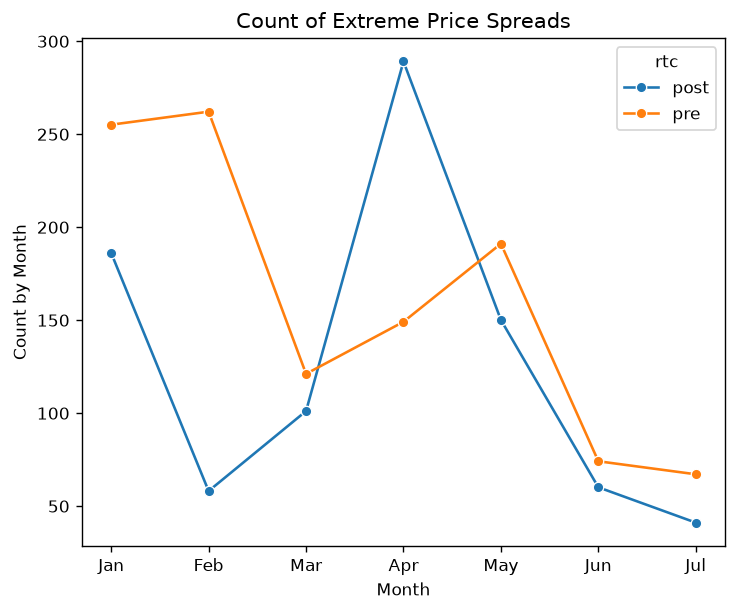

In [14]:
ercot_extreme = (
    ercot.groupby("time_utc", as_index = False)
    .agg(spread = ("price", lambda x: x.max() - x.min()))
    .assign(rtc = lambda x: np.where(x["time_utc"] < pd.Timestamp("12-05-2025"), "pre", "post"),
    ext_spread = lambda x: np.where(x['spread'] >= x.loc[x["rtc"] == "pre","spread"].quantile(.95), "extreme", "normal"),
    month = lambda x: x["time_utc"].dt.month)
    .query("((time_utc > '2025-01-01') & (time_utc < '2025-07-25')) | ((time_utc > '2026-01-01') & (time_utc < '2026-07-25'))")
    .groupby(["month", "rtc"], as_index=False)
    .agg(count_by_month =("ext_spread", lambda x: (x == "extreme").sum()))
)

fig, ax = plt.subplots(figsize=(6, 5))

sns.lineplot(
    data=ercot_extreme,
    x="month",
    y="count_by_month",
    hue="rtc",
    marker = "o",
    ax=ax
)

ax.set_title("Count of Extreme Price Spreads")
ax.set_ylabel("Count by Month")
ax.set_xlabel("Month")
ax.set_xticks([1, 2, 3, 4, 5, 6, 7])
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul"])

plt.tight_layout()
plt.show()


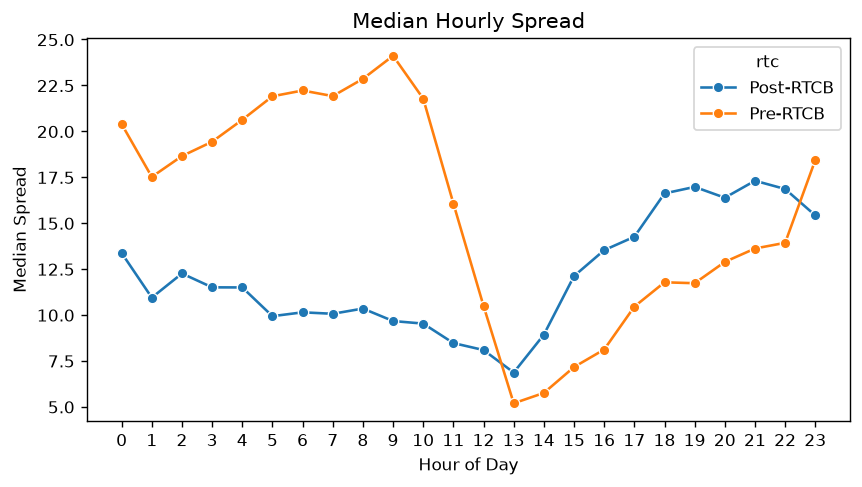

In [15]:
ercot_hourly_spread = (
    ercot.groupby("time_utc", as_index=False)
    .agg(spread = ("price", lambda x: x.max() - x.min()))
    .assign(rtc = lambda x: np.where(x["time_utc"] < pd.Timestamp("12-05-2025"), "Pre-RTCB", "Post-RTCB"),
    hour_utc = lambda x: x["time_utc"].dt.hour)
    .query("((time_utc > '2025-01-01') & (time_utc < '2025-07-25')) | ((time_utc > '2026-01-01') & (time_utc < '2026-07-25'))")
    .groupby(["hour_utc", "rtc"])
    .agg(hourly_median = ("spread", lambda x: x.median()))
)

fig, ax1 = plt.subplots(figsize=(7, 4))

sns.lineplot(
    data = ercot_hourly_spread,
    x = "hour_utc",
    y = "hourly_median",
    hue = "rtc",
    marker = "o",
    ax=ax1
)

ax1.set_title("Median Hourly Spread")
ax1.set_ylabel("Median Spread")
ax1.set_xlabel("Hour of Day")
ax1.set_xticks(range(24))
ax1.set_xticklabels(range(24))

plt.tight_layout()
plt.show()



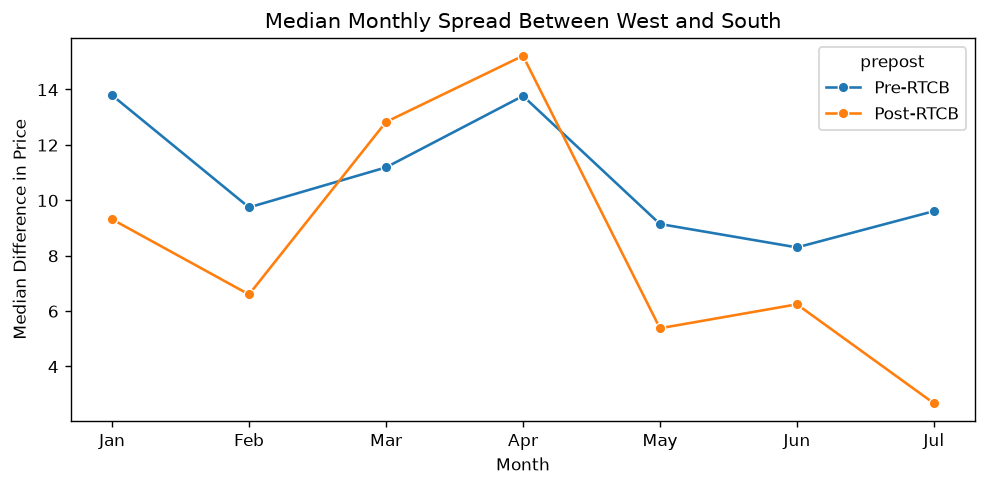

In [ ]:
ercot_plot_south = (
    ercot.pivot(index = ["time_utc"], columns = "spn", values = "price").reset_index()
    .assign(wdiff = lambda x: abs(x["LZ_WEST"] - x["LZ_SOUTH"]),
     month = lambda x: x["time_utc"].dt.month,
     prepost = lambda x: np.where(x["time_utc"] < pd.Timestamp("12-05-2025"), "Pre-RTCB", "Post-RTCB"))
    .query("month <= 7")
    .groupby(["month", "prepost"], as_index = False)
    .agg(ew = ("wdiff", lambda x: x.median()))

)

fig, ax2 = plt.subplots(figsize=(6, 5))

sns.lineplot(
        data = ercot_plot_south,
        x = "month",
        y = "ew",
        hue = "prepost",
        hue_order=  ["Pre-RTCB", "Post-RTCB"],
        marker = "o",
        ax = ax2
    )

ax2.set_title("Median Monthly Spread Between West and South")
ax2.set_ylabel("Median Difference in Price")
ax2.set_xlabel("Month")
ax2.set_xticks([1, 2, 3, 4, 5, 6, 7], ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul'])

plt.tight_layout()
plt.show()



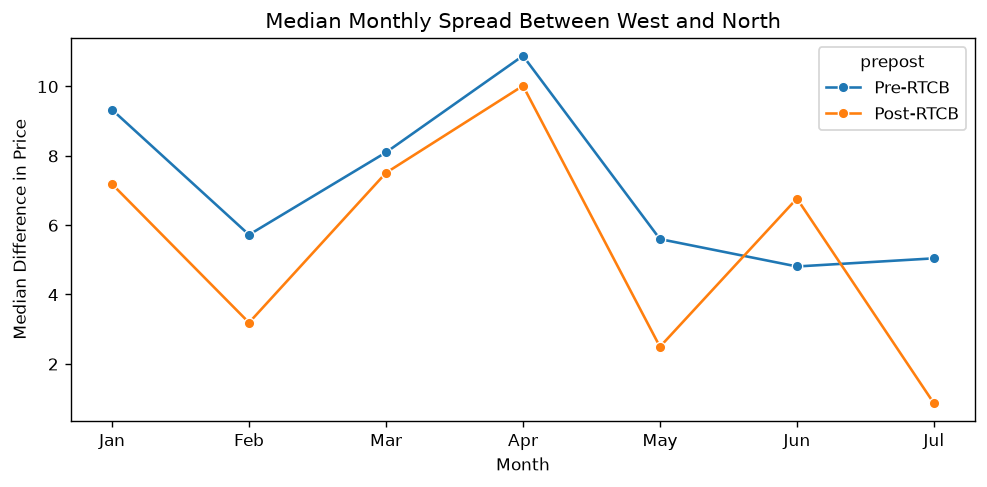

In [ ]:
ercot_plot_north = (
    ercot.pivot(index = ["time_utc"], columns = "spn", values = "price").reset_index()
    .assign(wdiff = lambda x: abs(x["LZ_WEST"] - x["LZ_NORTH"]),
     month = lambda x: x["time_utc"].dt.month,
     prepost = lambda x: np.where(x["time_utc"] < pd.Timestamp("12-05-2025"), "Pre-RTCB", "Post-RTCB"))
    .query("month <= 7")
    .groupby(["month", "prepost"], as_index = False)
    .agg(ew = ("wdiff", lambda x: x.median()))

)

fig, ax3 = plt.subplots(figsize=(6, 5))

sns.lineplot(
        data = ercot_plot_north,
        x = "month",
        y = "ew",
        hue = "prepost",
        hue_order=  ["Pre-RTCB", "Post-RTCB"],
        marker = "o",
        ax = ax3
    )

ax3.set_title("Median Monthly Spread Between West and North")
ax3.set_ylabel("Median Difference in Price")
ax3.set_xlabel("Month")
ax3.set_xticks([1, 2, 3, 4, 5, 6, 7], ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul'])

plt.tight_layout()
plt.show()


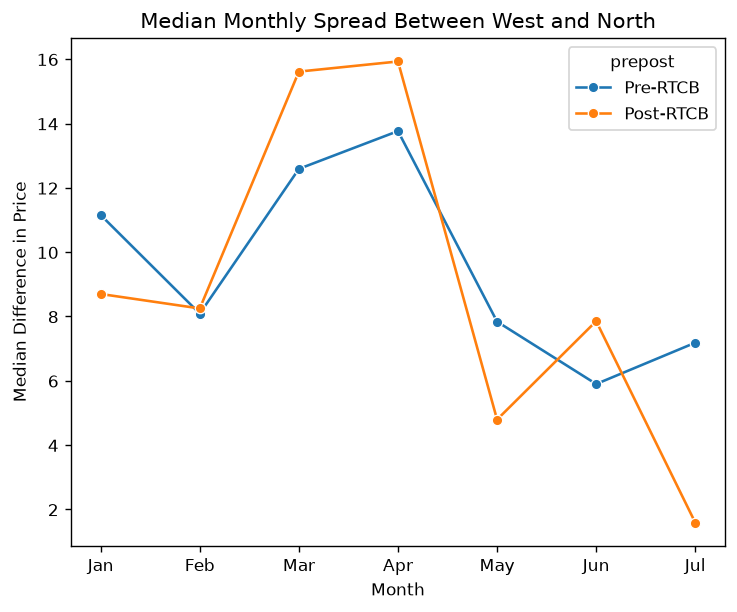

In [13]:
ercot_plot_houston = (
    ercot.pivot(index = ["time_utc"], columns = "spn", values = "price").reset_index()
    .assign(wdiff = lambda x: abs(x["LZ_WEST"] - x["LZ_HOUSTON"]),
     month = lambda x: x["time_utc"].dt.month,
     prepost = lambda x: np.where(x["time_utc"] < pd.Timestamp("12-05-2025"), "Pre-RTCB", "Post-RTCB"))
    .query("month <= 7")
    .groupby(["month", "prepost"], as_index = False)
    .agg(ew = ("wdiff", lambda x: x.median()))

)

fig, ax4 = plt.subplots(figsize=(6, 5))

sns.lineplot(
        data = ercot_plot_houston,
        x = "month",
        y = "ew",
        hue = "prepost",
        hue_order=  ["Pre-RTCB", "Post-RTCB"],
        marker = "o",
        ax = ax4
    )

ax4.set_title("Median Monthly Spread Between West and North")
ax4.set_ylabel("Median Difference in Price")
ax4.set_xlabel("Month")
ax4.set_xticks([1, 2, 3, 4, 5, 6, 7], ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul'])

plt.tight_layout()
plt.show()
